In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.formula.api as smf

In [3]:
col = pd.read_csv("../data/Ad_table.csv")

C:\Users\jchmo\AppData\Local\Temp\ipykernel_37076\2793523955.py:1: DtypeWarning: Columns (13) have mixed types. Specify dtype option on import or set low_memory=False.
  col = pd.read_csv("../data/Ad_table.csv")


In [4]:
col["car_age"] = col["Adv_year"] - col["Reg_year"]
col["Price"] = pd.to_numeric(col["Price"], errors="coerce")
col["Runned_Miles"] = pd.to_numeric(col["Runned_Miles"], errors="coerce")
col["Color"] = col["Color"].astype(str).str.strip().str.title()

In [5]:
col = col[
    col["car_age"].between(0, 15)
    & (col["Price"] > 500)
    & col["Runned_Miles"].between(0, 200_000)
].dropna(subset=["Color", "Price", "Runned_Miles", "Reg_year"])
col = col[~col["Color"].isin(["Nan", "Unlisted", "Other", "Multicolor"])]
col = col[~col["Genmodel"].isin(["Z3M", "Z4M", "Z8"])]

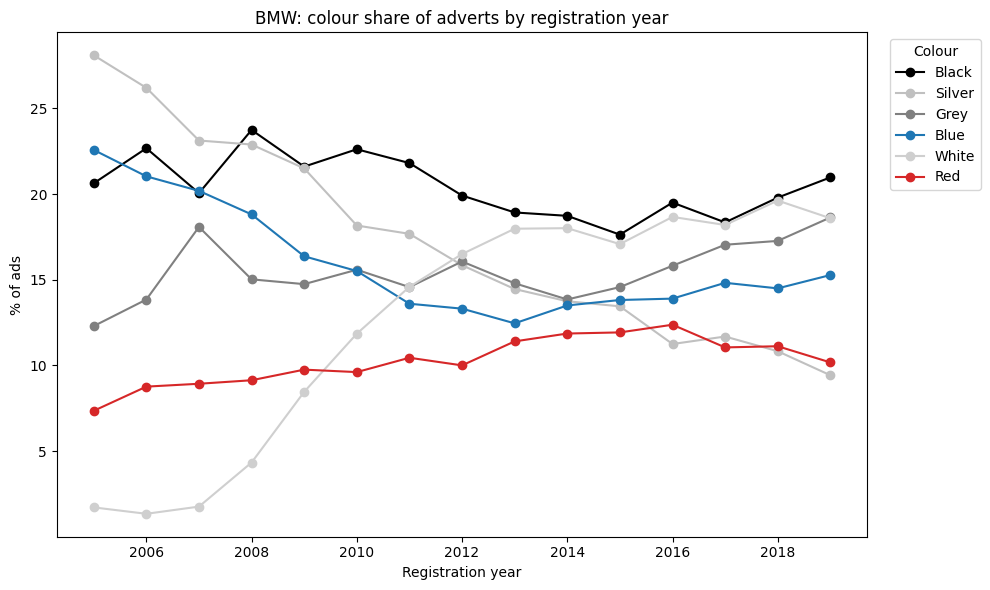

In [7]:
# --- 2. Popularity over time ---
top_colors = col["Color"].value_counts().head(6).index
pop = col[col["Reg_year"].between(2005, 2019)]
share = (pd.crosstab(pop["Reg_year"], pop["Color"], normalize="index") * 100)[top_colors]

colour_map = {
    "Black":  "black",
    "White":  "#cfcfcf",   # pure white would be invisible on a white background
    "Silver": "silver",
    "Grey":   "grey",
    "Blue":   "tab:blue",
    "Red":    "tab:red",
    "Green":  "tab:green",
    "Brown":  "saddlebrown",
    "Orange": "orange",
    "Yellow": "gold",
    "Beige":  "tan",
    "Bronze": "peru",
    "Purple": "purple",
}


line_colours = [colour_map.get(c, "tab:cyan") for c in share.columns]

ax = share.plot(figsize=(10, 6), marker="o", color=line_colours)
ax.set(title="BMW: colour share of adverts by registration year",
       ylabel="% of ads", xlabel="Registration year")
ax.legend(title="Colour", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.savefig("../images/bmw_colour_popularity.png", dpi=150)
plt.show()